In [1]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

In [2]:
import keras_cv

Using TensorFlow backend


C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
image_file = "Images/image_50402305.JPG"

In [10]:
tf_img = tf.io.read_file("Images/image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [19]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("Images/image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5
Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
8/8 [==============================] - 24s 2s/step


In [20]:
prediction_groups = prediction_groups[0]

---

In [21]:
# Define functions for dealing with images

image_width = 128
image_height = 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (128, 32, 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  slepy
538 994 96 163


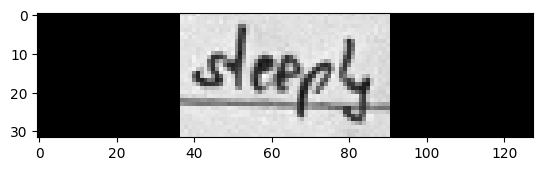

In [24]:
res = WordBox(prediction_groups[57])
DisplayWord(res)

In [25]:
word = res # This will be processed in the below code

# Pre-processing

In [26]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

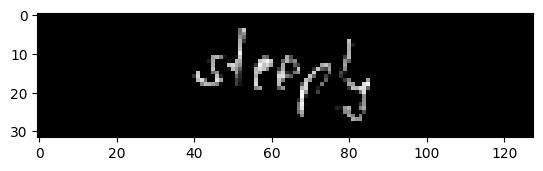

In [27]:
def BgChange(word, CleaningCoefficient):

    # The higher the CleaningCoefficient, the more of the dimmer features that are cleaned out

    image = [ [ 0 for i in range(len(word[i])) ]  for i in range(len(word))]

    for i in range(len(word)):
        for j in range(len(word[i])):
            # if word[i][j][0] > 0.6:
            #     tf.print(word[i][j][0])
            #     image[i][j] = [1]
            # else:
            #     image[i][j] = [0]

            temp = float(word[i][j][0]) * CleaningCoefficient

            if temp == 0:
                temp = 1

            if temp > 1:
                temp = 1

            image[i][j] = temp

    image = tf.constant(image)

    image = skimage.img_as_float(image)
    image = invert(image)

    DisplayWord(image)

    return image
    
image = BgChange(word, 3)

Remove Line (hasn't worked out as of yet)

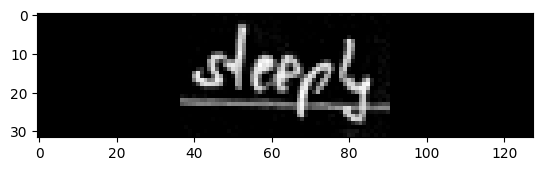

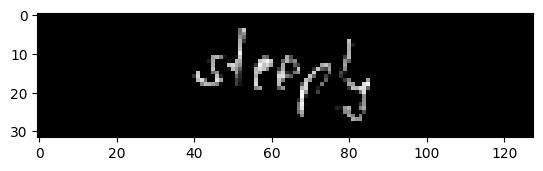

In [28]:
A = BgChange(word, 1.5)
B = BgChange(word, 3)

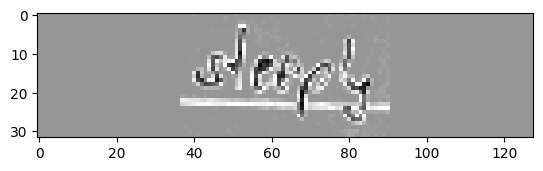

In [29]:
C = A - 2 * B

DisplayWord(C)



In [30]:
line_thickness=2

img = res

# Apply binary thresholding to get a binary image
binary_image = tf.where(img < 0.5, 0.0, 1.0)

# Create a horizontal kernel
kernel = tf.ones((1, line_thickness, 1, 1), dtype=tf.float32)

# Apply 1D convolution to detect horizontal lines
lines_detected = tf.nn.conv2d(binary_image[None, ..., None], kernel, strides=[1, 1, 1, 1], padding='SAME')[0, ..., 0]

# Set pixels corresponding to detected lines to 0
result_image = tf.where(lines_detected > 0, 0.0, img)


In [31]:
distribution = []

for i in result_image:
    sum = 0
    for j in range(len(i)):
        sum = sum + i[j][0]
    distribution.append(sum)

tf.print(distribution)

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0.847058833,
 0.826906323,
 0.827269435,
 1.89488029,
 1.63758171,
 1.10461152,
 1.17774141,
 2.3741827,
 2.58111858,
 2.86742926,
 2.28344131,
 1.9239651,
 1.0883081,
 1.31176484,
 4.23130226,
 4.047894,
 2.9758141,
 0.349019617,
 1.80250669,
 1.90370381,
 3.06012893,
 1.67726946,
 1.39934647,
 1.78307772,
 2.4186635,
 2.30315948,
 3.17494488,
 2.85591626,
 1.40294123,
 2.15642691,
 3.15051055,
 2.49182987,
 2.23798132,
 1.89248359,
 1.48529446,
 2.2070446,
 2.08453155,
 3.09204817,
 1.6276679,
 1.28583741,
 0.791176438,
 2.58878136,
 3.78152037,
 2.94357276,
 3.25987148,
 1.69371819,
 2.91394067,
 2.35159636,
 1.68122697,
 0.40065366,
 0.368373245,
 0.337799549,
 0.827559948,
 0.839288354,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]


Slope removal

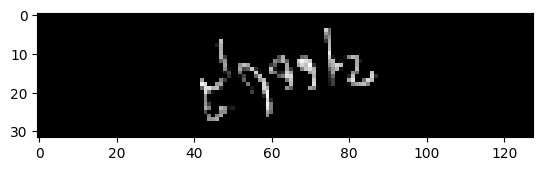

In [44]:
image = tf.reshape(image, (1,128,32))

rotated = tf.image.rot90(image, k=6)

DisplayWord(rotated)

In [34]:
from keras_cv.utils import preprocessing

ModuleNotFoundError: No module named 'keras_cv.utils'

In [32]:
# Required mod (image rotation)

def rotate(image):

    severity_factor = preprocessing.parse_factor(
        self.severity,
        min_value=0.01,
        max_value=1.0,
        param_name="severity",
        seed=123,
    )

    angle = tf.expand_dims(
        tf.cast(severity_factor() * 30, tf.float32), axis=0
    )
    shape = tf.cast(tf.shape(image), tf.float32)

    return preprocessing.transform(
        tf.expand_dims(image, 0),
        preprocessing.get_rotation_matrix(angle, shape[0], shape[1]),
    )[0]

ModuleNotFoundError: No module named 'keras_cv.utils'

Slant removal

In [36]:
# Begin from the findings from the paper

Make the characters 1 pixel wide

In [37]:
skeleton = thin(image, max_num_iter=1)

# or skeletonize(image)

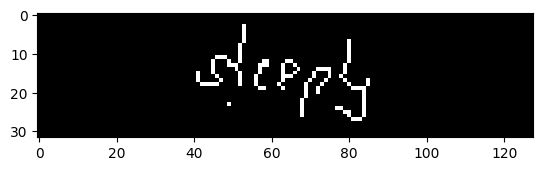

In [38]:
DisplayWord(skeleton)

In [39]:
skel, distance = medial_axis(image, return_distance=True)

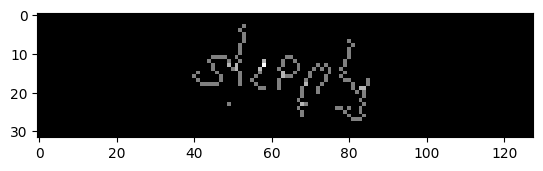

In [40]:
dist_on_skel = distance * skel
DisplayWord(dist_on_skel)

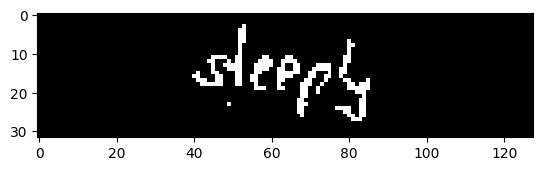

In [41]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))